# 00 · Sources, cleaning and real-data findings

What do we actually know about Afijio's public health centres, and what does national survey data say about medicine availability?

**Sources:** [GRID3/NHFR facility registry](https://services3.arcgis.com/9nfxWATFamVUTTGb/ArcGIS/rest/services/health_facilities_state_WFL1/FeatureServer/1) (public primary facilities in Afijio) and the [NBS National Health Facility Survey 2023 tables](https://microdata.nigerianstat.gov.ng/index.php/catalog/149/related-materials).

In [1]:
import hashlib
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from supplysignal.fetch_sources import fetch, fetch_nhfs
from supplysignal.pipeline import load_facilities

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT / "data/raw"
OUT = PROJECT / "reports/analysis"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, HIGHLIGHT = "#237a80", "#c35c43"

## 1. Load the sources and fingerprint them

The registry comes from the frozen snapshot in `data/snapshots/` (or is downloaded if absent); the NBS workbook is downloaded once. Hashing each file records exactly which bytes every result below is based on.

In [2]:
registry_path = RAW / "afijio_public_primary_arcgis.json"
nbs_path = RAW / "nhfs_2023_results_tables.xlsx"

if not registry_path.exists():
    snapshot = PROJECT / "data/snapshots/afijio_public_primary_arcgis.json"
    if snapshot.exists():
        RAW.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(snapshot, registry_path)
    else:
        fetch()
if not nbs_path.exists():
    fetch_nhfs()

fingerprints = pd.DataFrame([
    {"file": path.name, "bytes": path.stat().st_size, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in (registry_path, nbs_path)
])
fingerprints.to_csv(OUT / "source_fingerprints.csv", index=False)
fingerprints

,file,bytes,sha256
0,afijio_public_primary_arcgis.json,26813,ad04a6afbac0a42736711d2fa6abcf50df8175d55a0033...
1,nhfs_2023_results_tables.xlsx,689866,70a7716a39b4f6fb29c8c7ccb7a81f74a093152c482867...


## 2. Clean the registry

The query returns every public primary facility in Afijio. We keep the *Primary Health Center* subtype, which is the pilot scope. Missing or shared NHFR codes are reported rather than invented or merged, because a wrong join would attach stock reports to the wrong clinic.

In [3]:
payload = json.loads(registry_path.read_text())
assert not payload.get("exceededTransferLimit", False)
raw = pd.DataFrame([feature["attributes"] for feature in payload["features"]])
facilities = pd.DataFrame(load_facilities(registry_path))
assert facilities.facility_id.is_unique

codes = facilities.nhfr_code.fillna("").str.strip()
has_code = codes.ne("")
shared_code = codes[has_code].duplicated(keep=False)
out_of_range = ~facilities.latitude.between(4, 14) | ~facilities.longitude.between(2, 15)

audit = pd.DataFrame(
    [
        ["Records returned by the query", len(raw), "All public primary facilities in Afijio"],
        ["Primary health centres kept", len(facilities), "Pilot scope"],
        ["Other subtypes excluded", len(raw) - len(facilities), "Out of scope, not invalid"],
        ["Missing NHFR code", int((~has_code).sum()), "Kept; needs an agreed ID crosswalk before LMIS joins"],
        ["Records sharing an NHFR code", int(shared_code.sum()), "Kept separate; not merged"],
        ["Duplicated registry ID", int(facilities.facility_id.duplicated().sum()), "Must be zero"],
        ["Coordinates outside Nigeria", int(out_of_range.sum()), "Must be zero"],
    ],
    columns=["Check", "Records", "Decision"],
)
audit.to_csv(OUT / "cleaning_audit.csv", index=False)
audit

,Check,Records,Decision
0,Records returned by the query,47,All public primary facilities in Afijio
1,Primary health centres kept,28,Pilot scope
2,Other subtypes excluded,19,"Out of scope, not invalid"
3,Missing NHFR code,15,Kept; needs an agreed ID crosswalk before LMIS...
4,Records sharing an NHFR code,2,Kept separate; not merged
5,Duplicated registry ID,0,Must be zero
6,Coordinates outside Nigeria,0,Must be zero


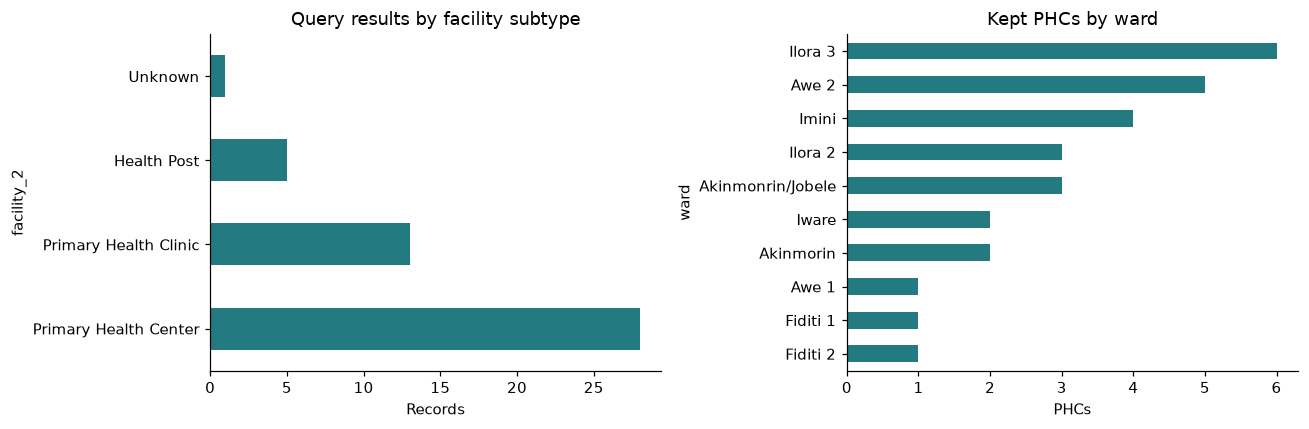

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw.facility_2.value_counts().plot.barh(ax=axes[0], color=TEAL, title="Query results by facility subtype")
facilities.ward.value_counts().sort_values().plot.barh(ax=axes[1], color=TEAL, title="Kept PHCs by ward")
axes[0].set_xlabel("Records")
axes[1].set_xlabel("PHCs")
fig.tight_layout()
plt.show()

## 3. Facility geography

Straight-line distances between PHCs show which clinics are close enough to be candidate donors for each other. They are a screen only; road access and travel time are confirmed by the officer.

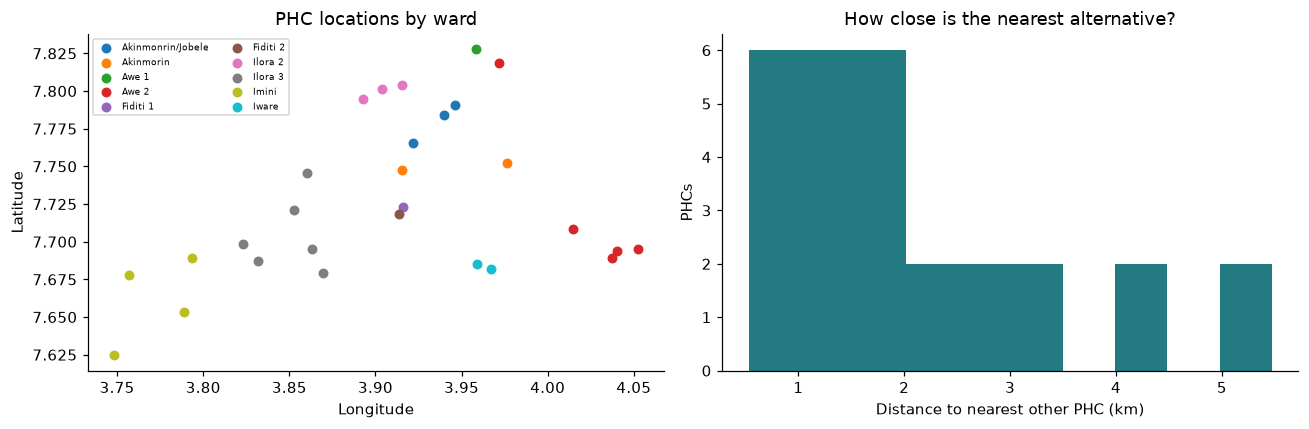

Median distance to the nearest other PHC: 1.7 km
Largest distance between any two PHCs: 34.4 km


In [5]:
lat = np.radians(facilities.latitude.to_numpy())
lon = np.radians(facilities.longitude.to_numpy())
haversine = (
    np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
    + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lon[:, None] - lon[None, :]) / 2) ** 2
)
distance_km = 6371 * 2 * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))
np.fill_diagonal(distance_km, np.inf)
nearest_km = distance_km.min(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ward, group in facilities.groupby("ward"):
    axes[0].scatter(group.longitude, group.latitude, label=ward, s=30)
axes[0].set(xlabel="Longitude", ylabel="Latitude", title="PHC locations by ward")
axes[0].legend(fontsize=6, ncol=2)
axes[1].hist(nearest_km, bins=10, color=TEAL)
axes[1].set(xlabel="Distance to nearest other PHC (km)", ylabel="PHCs", title="How close is the nearest alternative?")
fig.tight_layout()
plt.show()

print(f"Median distance to the nearest other PHC: {np.median(nearest_km):.1f} km")
print(f"Largest distance between any two PHCs: {distance_km[np.isfinite(distance_km)].max():.1f} km")

## 4. Essential-medicine availability by state (NBS 2023)

The survey reports the **average share of listed essential drugs available** in each state's public primary facilities. We read the original sheet and check its headers before extracting, because each table block in the workbook has its own state column.

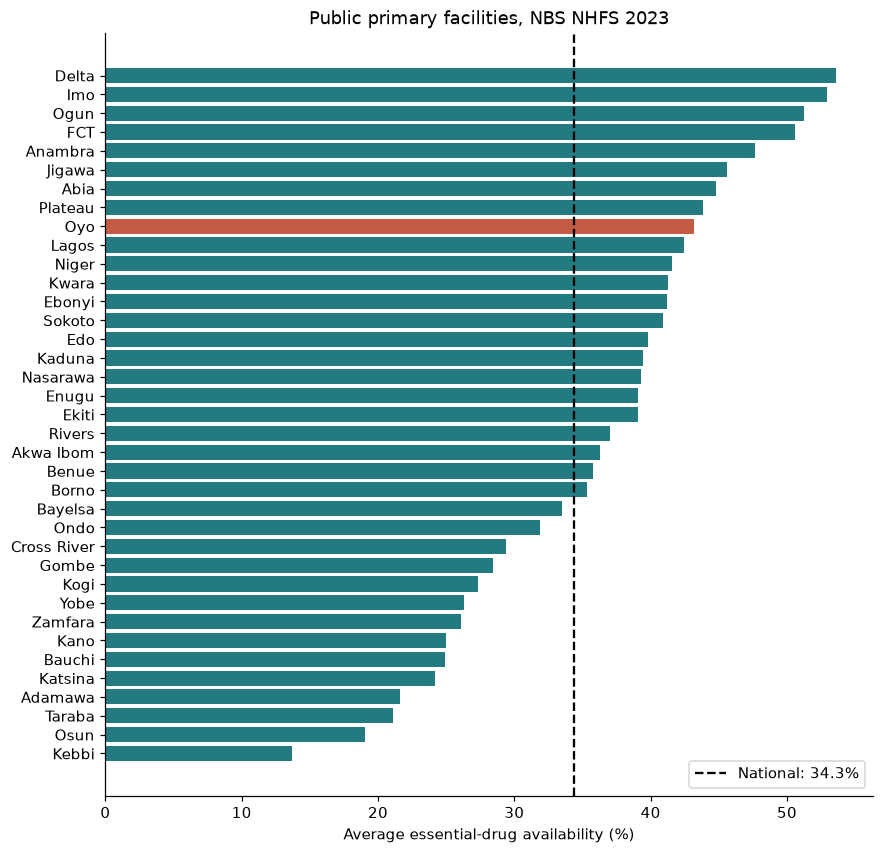

National average: 34.3%  ·  Oyo: 43.2%


In [6]:
sheet = pd.read_excel(nbs_path, sheet_name="Drugs and Equipment", header=None)
assert "Average Proportion of Essential Drugs" in str(sheet.iloc[1, 0])
assert sheet.iloc[2, 2] == "Public Primary"

essential = sheet.iloc[3:40, [1, 2, 3]].copy()
essential.columns = ["state", "public_primary_pct", "public_secondary_pct"]
essential[["public_primary_pct", "public_secondary_pct"]] = essential[["public_primary_pct", "public_secondary_pct"]].apply(pd.to_numeric)
assert len(essential) == 37 and essential.state.is_unique
national_pct = float(sheet.loc[sheet[1].eq("Total"), 2].iloc[0])
oyo_pct = float(essential.loc[essential.state.eq("Oyo"), "public_primary_pct"].iloc[0])
essential.to_csv(OUT / "nbs_essential_availability.csv", index=False)

ordered = essential.sort_values("public_primary_pct")
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(ordered.state, ordered.public_primary_pct, color=[HIGHLIGHT if state == "Oyo" else TEAL for state in ordered.state])
ax.axvline(national_pct, color="black", linestyle="--", label=f"National: {national_pct:.1f}%")
ax.set(xlabel="Average essential-drug availability (%)", title="Public primary facilities, NBS NHFS 2023")
ax.legend()
plt.show()

print(f"National average: {national_pct:.1f}%  ·  Oyo: {oyo_pct:.1f}%")

## 5. Maternal medicines in Oyo

Oxytocin and magnesium sulfate are the survey's maternal tracer medicines, and two of the three products in the prototype.

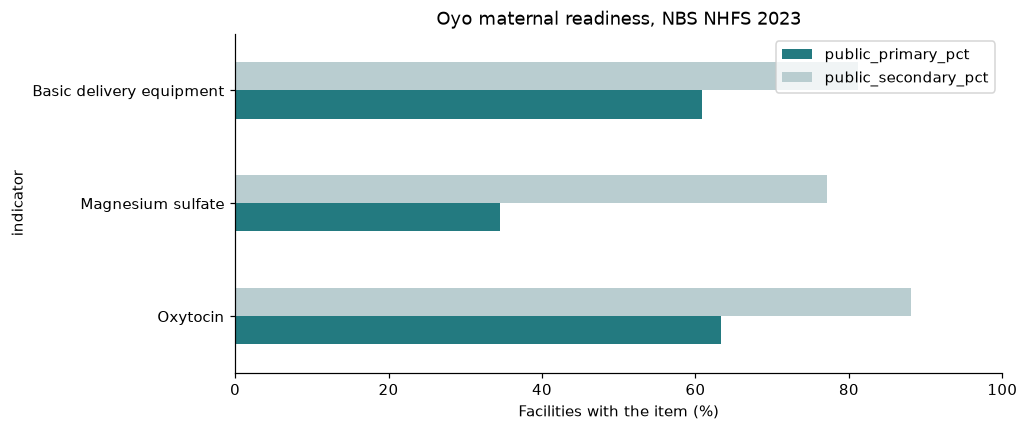

,indicator,public_primary_pct,public_secondary_pct
0,Oxytocin,63.285786,88.048981
1,Magnesium sulfate,34.513766,77.154643
2,Basic delivery equipment,60.806107,81.205743


In [7]:
maternal = pd.read_excel(nbs_path, sheet_name="Drugs and Equipment_ D", header=None)
assert maternal.iloc[3, 29] == "oxytocin" and maternal.iloc[3, 33] == "mgso4"
assert maternal.iloc[2, 29] == "Public Primary" and maternal.iloc[2, 33] == "Public Primary"
oyo_row = maternal.loc[maternal[28].astype(str).str.strip().eq("Oyo")].iloc[0]

tracers = pd.DataFrame({
    "indicator": ["Oxytocin", "Magnesium sulfate", "Basic delivery equipment"],
    "public_primary_pct": [float(oyo_row[29]), float(oyo_row[33]), float(oyo_row[41])],
    "public_secondary_pct": [float(oyo_row[30]), float(oyo_row[34]), float(oyo_row[42])],
})
tracers.to_csv(OUT / "nbs_oyo_maternal.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
tracers.set_index("indicator").plot.barh(ax=ax, color=[TEAL, "#b9cdd0"])
ax.set(xlabel="Facilities with the item (%)", title="Oyo maternal readiness, NBS NHFS 2023", xlim=(0, 100))
plt.show()
tracers

## 6. Save the key figures

These numbers are reused in the write-up and later notebooks.

In [8]:
findings = {
    "raw_records": len(raw),
    "retained_phcs": len(facilities),
    "missing_nhfr": int((~has_code).sum()),
    "duplicate_code_records": int(shared_code.sum()),
    "oyo_essential_pct": oyo_pct,
    "national_public_primary_pct": national_pct,
    "oyo_oxytocin_pct": float(oyo_row[29]),
    "oyo_magnesium_pct": float(oyo_row[33]),
    "max_pair_distance_km": float(distance_km[np.isfinite(distance_km)].max()),
}
(OUT / "real_findings.json").write_text(json.dumps(findings, indent=2))
findings

{'raw_records': 47,
 'retained_phcs': 28,
 'missing_nhfr': 15,
 'duplicate_code_records': 2,
 'oyo_essential_pct': 43.21072321462795,
 'national_public_primary_pct': 34.34549861794788,
 'oyo_oxytocin_pct': 63.28578629018344,
 'oyo_magnesium_pct': 34.51376575277223,
 'max_pair_distance_km': 34.39294879635126}

## What this means

- **The problem is real.** Public primary facilities nationally have only about a third of essential medicines available on average, and maternal tracers are far from universal in Oyo.
- **Identity needs care.** About half the PHCs have no NHFR code, so real LMIS imports join through an agreed facility crosswalk rather than NHFR codes alone.
- **Nearby donors exist.** Most PHCs have another PHC within a few kilometres, which makes local redistribution a realistic option once stock is verified.
- **No facility stock history is public.** The monthly stock data used in the next notebooks is therefore simulated, while the facilities themselves are real.